# Serie I: segmentos de variedades y lectura gerencial

**Borrador con revisión independiente pendiente.** La segmentación utiliza solo el dataset entregado. Para comparar comportamientos se consideran ensayos de etapa 5, plantía y dos socas, con al menos dos años y dos localidades por variedad/corte. Las variedades con menor cobertura se conservan en una lista de evidencia insuficiente, sin inventar su longevidad.

Cada variedad se representa con cuatro dimensiones: productividad media de azúcar por acre, calidad TRS (lb azúcar/ton caña), conservación de rendimiento en segunda soca respecto a plantía y variabilidad relativa entre ambientes. Se da igual peso a los tres cortes al resumir productividad/calidad. La fibra queda fuera del agrupamiento por su ausencia extensa; se conserva en los datos y no se rellena para forzar su uso.

In [1]:
import sys
print("Python de ejecución:", sys.executable)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RUTA = Path("../data/processed/serie1_etl_provisional.csv")
if not RUTA.exists():
    RUTA = Path("data/processed/serie1_etl_provisional.csv")
datos = pd.read_csv(RUTA, low_memory=False)
etapa5 = datos.loc[datos["STAGE"].eq(5)].copy()
excluir = etapa5["REQUIERE_REVISION"] | etapa5[["T_SPACRE", "TRS_TON"]].isna().any(axis=1)
filas_excluidas = etapa5.loc[excluir].copy()
filas_excluidas["MOTIVO_EXCLUSION_ANALISIS"] = np.where(
    filas_excluidas[["T_SPACRE", "TRS_TON"]].isna().any(axis=1),
    "Falta productividad o calidad para perfilar.", "Alerta de calidad en el escenario principal."
)
filas_excluidas.to_csv(RUTA.parent / "serie1_segmentacion_exclusiones.csv", index=False)
base = etapa5.loc[~excluir]
ambientes = base.groupby(["CLONE", "CROP", "YEAR", "LOC"], as_index=False)[["T_SPACRE", "TRS_TON"]].mean()
cobertura = ambientes.groupby(["CLONE", "CROP"]).agg(anios=("YEAR", "nunique"), localidades=("LOC", "nunique"))
elegibles, no_elegibles = [], []
for clon, grupo in cobertura.groupby(level="CLONE"):
    cortes = grupo.droplevel("CLONE")
    faltan = [c for c in range(3) if c not in cortes.index or cortes.loc[c, "anios"] < 2 or cortes.loc[c, "localidades"] < 2]
    if faltan:
        no_elegibles.append({"CLONE": clon, "MOTIVO": f"Cobertura insuficiente en CROP={faltan}; se requieren dos años y localidades."})
    else:
        elegibles.append(clon)
pd.DataFrame(no_elegibles).to_csv(RUTA.parent / "serie1_variedades_sin_segmento.csv", index=False)
ambientes = ambientes.loc[ambientes["CLONE"].isin(elegibles) & ambientes["CROP"].le(2)].copy()
ambientes["INDICE_AMBIENTE"] = ambientes["T_SPACRE"] / ambientes.groupby(["CROP", "YEAR", "LOC"])["T_SPACRE"].transform("median")
ambientes["DESVIO_AMBIENTE"] = ambientes["INDICE_AMBIENTE"] - ambientes.groupby(["CLONE", "CROP"])["INDICE_AMBIENTE"].transform("mean")
medias_corte = ambientes.groupby(["CLONE", "CROP"])[["T_SPACRE", "TRS_TON"]].mean()
perfil = medias_corte.groupby("CLONE")[["T_SPACRE", "TRS_TON"]].mean().rename(columns={"T_SPACRE": "PRODUCTIVIDAD_LB_ACRE", "TRS_TON": "CALIDAD_LB_TON"})
perfil["CONSERVACION_SEGUNDA_SOCA"] = medias_corte["T_SPACRE"].unstack()[2] / medias_corte["T_SPACRE"].unstack()[0]
perfil["INESTABILIDAD_RELATIVA"] = ambientes.groupby("CLONE")["DESVIO_AMBIENTE"].std()
variables = perfil.columns.tolist()
print(f"Variedades en etapa 5: {etapa5['CLONE'].nunique()}; segmentadas: {len(perfil)}; conservadas sin segmento: {len(no_elegibles)}.")
display(perfil.round(3))

Python de ejecución: C:\Users\user\Desktop\Cursos\cesar\otros\yo\Prueba Santa Ana\.venv\Scripts\python.exe


Variedades en etapa 5: 40; segmentadas: 17; conservadas sin segmento: 23.


,PRODUCTIVIDAD_LB_ACRE,CALIDAD_LB_TON,CONSERVACION_SEGUNDA_SOCA,INESTABILIDAD_RELATIVA
CLONE,,,,
HO05-961,8225.142,290.769,0.836,0.104
HO07-613,8135.057,294.314,0.695,0.126
HO12-615,8919.366,262.691,0.786,0.090
HO13-739,8089.264,274.981,0.803,0.089
HOCP00-950,7994.772,307.007,0.779,0.106
HOCP04-838,8097.584,276.687,0.768,0.101
HOCP09-804,8432.763,284.402,0.860,0.112
HOCP14-885,9013.807,279.547,0.805,0.110
HOCP96-540,7494.360,267.151,0.712,0.153


## Selección del número de segmentos

Las cuatro dimensiones se estandarizan para que una escala grande no domine la distancia. Se comparan K-means con 2, 3 y 4 grupos. Se elige la mayor silueta entre soluciones con al menos tres variedades en cada grupo; así se evita convertir una sola variedad en un supuesto segmento gerencial. La restricción evita grupos demasiado pequeños para esta muestra; no demuestra que dos sea el número verdadero de clases. La silueta es una medida interna, no una comprobación de que existan clases biológicas naturales.

,K,SILUETA,MIN_VARIETADES_GRUPO
0,2,0.300,4
1,3,0.269,2
2,4,0.302,1


Número de segmentos elegido: 2


,variedades,productividad,calidad,conservacion,inestabilidad
SEGMENTO,,,,,
Perfil 1,4,7939.952,289.983,0.743,0.126
Perfil 2,13,8364.598,277.915,0.816,0.098


Perfil 1: HO07-613, HOCP00-950, HOCP96-540, L03-371
Perfil 2: HO05-961, HO12-615, HO13-739, HOCP04-838, HOCP09-804, HOCP14-885, L01-283, L01-299, L11-183, L12-201, L14-267, L99-226, L99-233


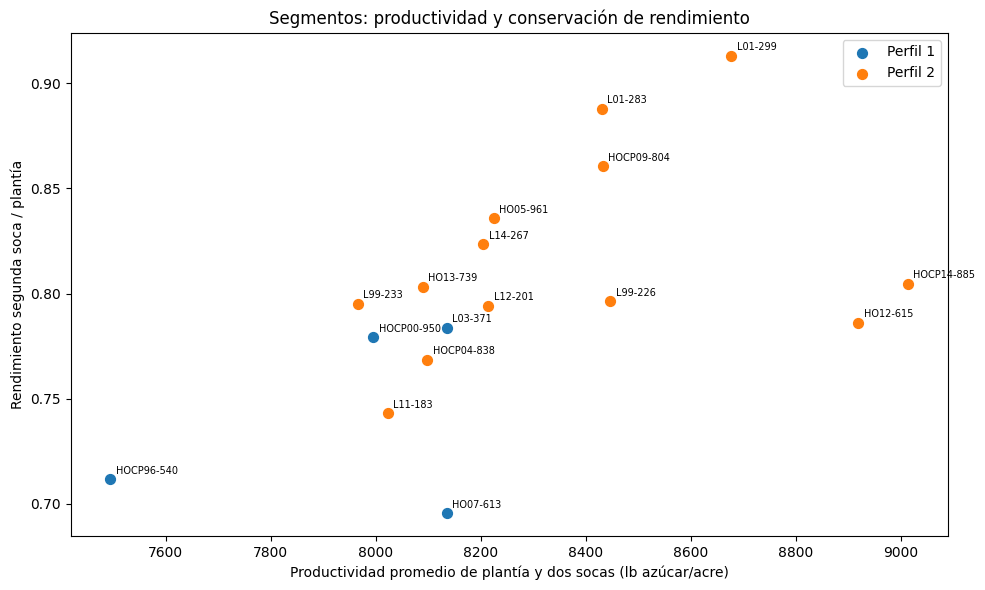

In [2]:
escalados = StandardScaler().fit_transform(perfil[variables])
comparacion = []
ajustes = {}
for k in [2, 3, 4]:
    ajuste = KMeans(n_clusters=k, n_init=30, random_state=42).fit(escalados)
    ajustes[k] = ajuste
    comparacion.append({"K": k, "SILUETA": silhouette_score(escalados, ajuste.labels_), "MIN_VARIETADES_GRUPO": pd.Series(ajuste.labels_).value_counts().min()})
comparacion = pd.DataFrame(comparacion)
display(comparacion.round(3))
k_elegido = int(comparacion.loc[comparacion["MIN_VARIETADES_GRUPO"].ge(3)].sort_values("SILUETA", ascending=False).iloc[0]["K"])
perfil["GRUPO"] = ajustes[k_elegido].labels_
orden = perfil.groupby("GRUPO")["CONSERVACION_SEGUNDA_SOCA"].mean().sort_values().index.tolist()
nombres = {grupo: f"Perfil {pos + 1}" for pos, grupo in enumerate(orden)}
perfil["SEGMENTO"] = perfil["GRUPO"].map(nombres)
resumen = perfil.groupby("SEGMENTO").agg(
    variedades=("GRUPO", "size"), productividad=("PRODUCTIVIDAD_LB_ACRE", "mean"),
    calidad=("CALIDAD_LB_TON", "mean"), conservacion=("CONSERVACION_SEGUNDA_SOCA", "mean"),
    inestabilidad=("INESTABILIDAD_RELATIVA", "mean"),
)
print("Número de segmentos elegido:", k_elegido)
display(resumen.round(3))
for segmento, grupo in perfil.groupby("SEGMENTO"):
    print(segmento + ": " + ", ".join(grupo.index.tolist()))
perfil.to_csv(RUTA.parent / "serie1_segmentos_variedades.csv")
resumen.to_csv(RUTA.parent / "serie1_perfiles_segmentos.csv")
comparacion.to_csv(RUTA.parent / "serie1_comparacion_segmentos.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 6))
for segmento, grupo in perfil.groupby("SEGMENTO"):
    ax.scatter(grupo["PRODUCTIVIDAD_LB_ACRE"], grupo["CONSERVACION_SEGUNDA_SOCA"], label=segmento, s=50)
    for clon, fila in grupo.iterrows():
        ax.annotate(clon, (fila["PRODUCTIVIDAD_LB_ACRE"], fila["CONSERVACION_SEGUNDA_SOCA"]), xytext=(4, 4), textcoords="offset points", fontsize=7)
ax.set(xlabel="Productividad promedio de plantía y dos socas (lb azúcar/acre)", ylabel="Rendimiento segunda soca / plantía", title="Segmentos: productividad y conservación de rendimiento")
ax.legend()
fig.tight_layout()
plt.show()

## Evaluación para Gerencia

Los segmentos son perfiles de comportamiento, no un ranking económico. `Perfil 1` reúne las variedades con menor conservación media en segunda soca; `Perfil 2` reúne las de mayor conservación. La tabla permite comprobar también diferencias de calidad y variabilidad, sin suponerlas por el nombre del grupo.

Para el perfil con mayor caída/variabilidad, conviene presupuestar la siguiente soca con mayor cautela y revisar renovación frente a un umbral económico, aunque algunas variedades tengan TRS atractivo. Para el perfil con mejor conservación y estabilidad, conviene evaluar mantener socas dentro del horizonte respaldado y priorizar seguimiento de producción. Dentro de cada segmento la elección final se hace con el aporte económico y el riesgo, no solo por pertenecer a un grupo.

El cociente segunda soca/plantía es una medida descriptiva de longevidad con muestras de ambientes distintos, no una pérdida causal de una misma parcela. La variabilidad se mide respecto a otros clones del mismo ambiente y se centra por clon/corte; así la diferencia media entre plantía y socas no se confunde completamente con inestabilidad ambiental. Hay pocos clones elegibles; los segmentos pueden cambiar al acumular años o corregir datos. La ausencia de fibra y de causas de descarte reduce la interpretación. Estas limitaciones se convierten en el plan de datos propios de la pregunta 4.

Con estos datos se eligen **dos segmentos** (silueta cercana a 0.30): **Perfil 1**, cuatro variedades con mayor TRS medio (aprox. 290 lb/ton), menor productividad (7,940 lb/acre), conservación de 74 % y más variabilidad; y **Perfil 2**, trece variedades con productividad mayor (8,365 lb/acre), TRS menor (278 lb/ton), conservación de 82 % y menor variabilidad. El primero plantea un intercambio entre calidad y longevidad; el segundo respalda explorar permanencia en soca con vigilancia económica. Las tres variedades recomendadas pertenecen al Perfil 2. Los grupos son amplios y no sustituyen la comparación individual.